# Insurance Charges Prediction  Complete Practical


In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully.")

Libraries imported successfully.


In [6]:
DATA_PATH = Path("insurance.csv")  # Change this to the full CSV path if necessary.
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Cannot find {DATA_PATH.resolve()}. Put insurance.csv beside this notebook or update DATA_PATH.")

df = pd.read_csv(DATA_PATH)
print("First five rows:")
display(df.head())
print("\nDataset information:")
df.info()
print("\nSummary statistics:")
display(df.describe())
print("\nMissing values:")
display(df.isnull().sum())

First five rows:


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB

Summary statistics:


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010



Missing values:


age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [7]:
required_columns = ["age", "sex", "bmi", "children", "smoker", "region", "charges"]
missing_columns = [c for c in required_columns if c not in df.columns]
if missing_columns:
    raise ValueError(f"Dataset is missing these expected columns: {missing_columns}")

df = df[required_columns].dropna().copy()
df_encoded = pd.get_dummies(df, columns=["sex", "smoker", "region"], drop_first=True, dtype=int)
display(df_encoded.head())
print(df_encoded.columns.tolist())

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,0,1,0,0,1
1,18,33.770,1,1725.55230,1,0,0,1,0
2,28,33.000,3,4449.46200,1,0,0,1,0
3,33,22.705,0,21984.47061,1,0,1,0,0
4,32,28.880,0,3866.85520,1,0,1,0,0


['age', 'bmi', 'children', 'charges', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']


In [8]:
X = df_encoded.drop(columns=["charges"])
y = df_encoded["charges"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (1070, 8)
Testing features: (268, 8)
Training target: (1070,)
Testing target: (268,)


In [10]:
model = LinearRegression()
model.fit(X_train, y_train)
print("Model trained successfully.\n")
for feature, coefficient in zip(X.columns, model.coef_):
    print(f"{feature}: {coefficient:.4f}")
print(f"\nModel intercept: {model.intercept_:.4f}")

Model trained successfully.

age: 256.9757
bmi: 337.0926
children: 425.2788
sex_male: -18.5917
smoker_yes: 23651.1289
region_northwest: -370.6773
region_southeast: -657.8643
region_southwest: -809.7994

Model intercept: -11931.2191


In [11]:
equation = f"charges = {model.intercept_:.4f}"
for feature, coefficient in zip(X.columns, model.coef_):
    sign = "+" if coefficient >= 0 else "-"
    equation += f" {sign} {abs(coefficient):.4f}({feature})"
print(equation)

charges = -11931.2191 + 256.9757(age) + 337.0926(bmi) + 425.2788(children) - 18.5917(sex_male) + 23651.1289(smoker_yes) - 370.6773(region_northwest) - 657.8643(region_southeast) - 809.7994(region_southwest)


In [12]:
y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f"MAE: {mae:,.2f}")
print(f"MSE: {mse:,.2f}")
print(f"R²: {r2:.4f}")
print(f"R² percentage: {r2 * 100:.2f}%")

MAE: 4,181.19
MSE: 33,596,915.85
R²: 0.7836
R² percentage: 78.36%


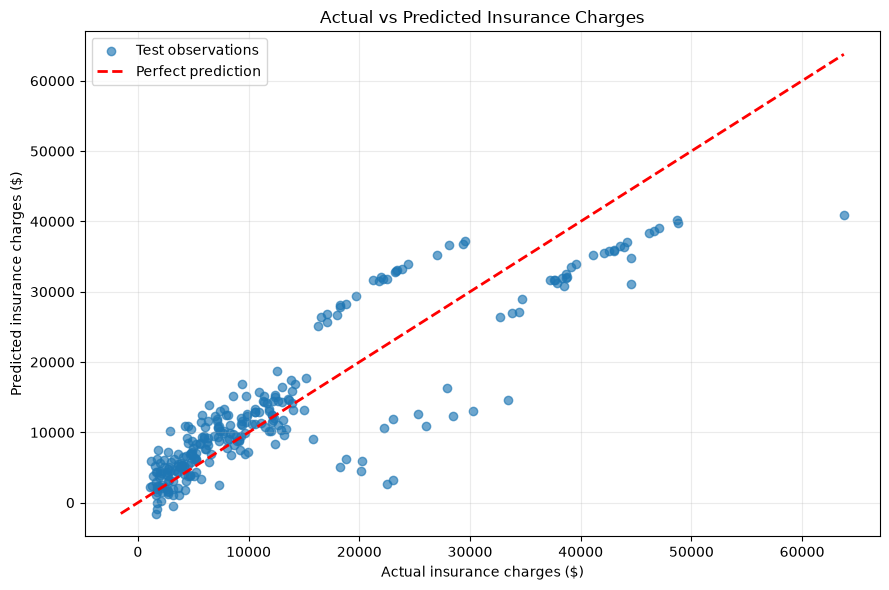

In [13]:
plt.figure(figsize=(9, 6))
plt.scatter(y_test, y_pred, alpha=0.65, label="Test observations")
low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())
plt.plot([low, high], [low, high], "r--", linewidth=2, label="Perfect prediction")
plt.xlabel("Actual insurance charges ($)")
plt.ylabel("Predicted insurance charges ($)")
plt.title("Actual vs Predicted Insurance Charges")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("regression_actual_vs_predicted.png", dpi=300)
plt.show()

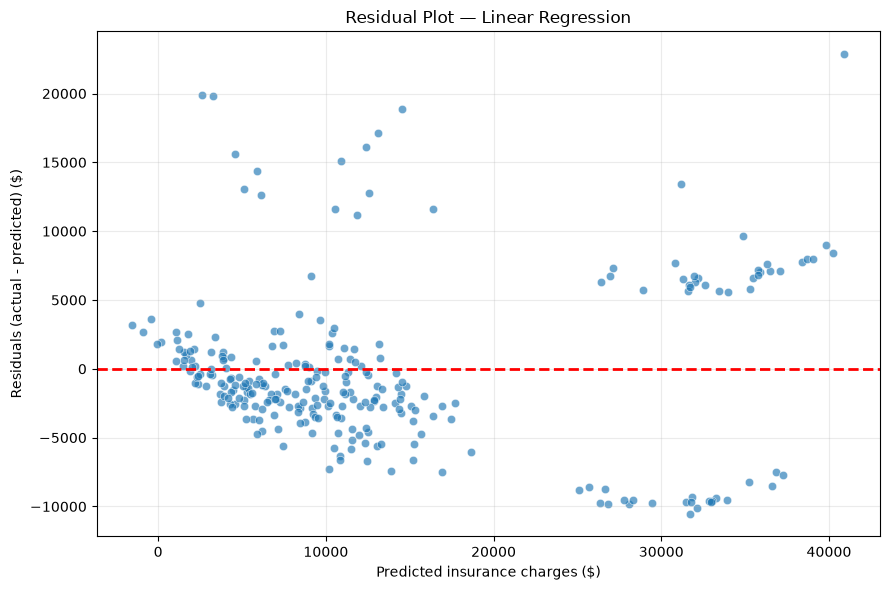

In [14]:
residuals = y_test - y_pred
plt.figure(figsize=(9, 6))
sns.scatterplot(x=y_pred, y=residuals, alpha=0.65)
plt.axhline(y=0, color="red", linestyle="--", linewidth=2)
plt.xlabel("Predicted insurance charges ($)")
plt.ylabel("Residuals (actual - predicted) ($)")
plt.title("Residual Plot — Linear Regression")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("regression_residual_plot.png", dpi=300)
plt.show()

In [15]:
new_person = pd.DataFrame([{
    "age": 19, "sex": "female", "bmi": 27.9,
    "children": 0, "smoker": "yes", "region": "southwest"
}])
new_person_encoded = pd.get_dummies(
    new_person, columns=["sex", "smoker", "region"],
    drop_first=True, dtype=int
)
new_person_encoded = new_person_encoded.reindex(columns=X.columns, fill_value=0)
predicted_charge = model.predict(new_person_encoded)[0]
display(new_person)
print(f"Predicted insurance charge: ${predicted_charge:,.2f}")

,age,sex,bmi,children,smoker,region
0,19,female,27.9,0,yes,southwest


Predicted insurance charge: $2,356.20


In [16]:
results = pd.DataFrame({
    "actual_charges": y_test.to_numpy(),
    "predicted_charges": y_pred
})
results.to_csv("insurance_prediction_results.csv", index=False)
print("Saved insurance_prediction_results.csv and both graph images.")

Saved insurance_prediction_results.csv and both graph images.
